# 13. Income Retention and Development Cost Comparison

This notebook tests whether rising development costs still change outcomes after recurring expenses reduce spendable income. I compare constant, linear, and quadratic development costs with 40%, 60%, and 80% income retention, using the existing fixed policies. The 60% case is the leading reference scenario; 40% and 80% are sensitivity cases. These retention values remain synthetic assumptions.

## What changes and what stays fixed

For each year, the model first applies environmental damage to gross income. The retained fraction is added to currency, and the remainder is treated as a recurring expense. Development cost is then set by one of these existing curves:

- Constant: `C = 25`
- Linear: `C = 25 * (1 + x)`
- Quadratic: `C = 25 * (1 + x)^2`

where `x = (EDI - initial_EDI) / (100 - initial_EDI)`.

The pollutant equations, damage settings, initial currency, investment prices, project schedule, and fixed policies remain the same across the comparison. Each run uses the same deterministic initial conditions. No agents are trained.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.baseline_regression import (REFERENCE_BASELINE_SETTINGS, REFERENCE_BASELINE_POLICIES,
                                                            compare_reference_baseline)

from study_3_pollutant_dynamics.config import EnvironmentConfig
from study_3_pollutant_dynamics.development_costs import DEVELOPMENT_COST_SHAPES
from study_3_pollutant_dynamics.economic_parameters import REGIONAL_ECONOMIC_PARAMETERS
from study_3_pollutant_dynamics.integrated_environment import Study3IntegratedEnvironment
from study_3_pollutant_dynamics.policy_evaluation import (FIXED_POLICY_NAMES, run_fixed_policy_episode,
                                                          summarize_integrated_episode)
from study_3_pollutant_dynamics.scenario_parameters import get_parameters

## Experiment settings

The grid uses 20-, 40-, and 60-year episodes, three fixed policies, and three income-retention levels. The cost shape is the only development equation that changes within a retention level. Since the environment is deterministic, the seed is held at 0 for reproducibility.

In [2]:
RETENTION_FRACTIONS = [0.4, 0.6, 0.8]
HORIZONS = [20, 40, 60]
POLICIES = []

for policy_name in FIXED_POLICY_NAMES:
    if policy_name in REFERENCE_BASELINE_POLICIES:
        POLICIES.append(policy_name)

SEED = REFERENCE_BASELINE_SETTINGS["seed"]
STARTING_CURRENCY_MULTIPLIER = REFERENCE_BASELINE_SETTINGS["starting_currency_multiplier"]
PURCHASE_FREQUENCY_YEARS = 5

In [3]:
def calculate_retention_totals(trajectory):
    gross_income_total = 0.0
    net_income_total = 0.0
    retained_income_total = 0.0
    recurring_expense_total = 0.0

    for info in trajectory:
        for region_result in info["regional_economy"]:
            gross_income_total += region_result["gross_income"]
            net_income_total += region_result["net_income"]
            retained_income_total += region_result["retained_income"]
            recurring_expense_total += region_result["recurring_expense"]

    totals = {
        "gross_income": gross_income_total,
        "net_income": net_income_total,
        "retained_income": retained_income_total,
        "recurring_expenses": recurring_expense_total,
    }

    return totals

In [4]:
def collect_retention_regional_results(trajectory, environment, retention_fraction, cost_shape, policy_name, horizon):
    regional_rows = []

    for region_index, region_parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        region_net_income = 0.0
        region_retained_income = 0.0
        region_recurring_expenses = 0.0

        development_requests = 0
        affordable_development = 0
        minimum_cash_cost_ratio = float("inf")
        region_packages = 0

        for info in trajectory:
            region_result = info["regional_economy"][region_index]

            region_net_income += region_result["net_income"]
            region_retained_income += region_result["retained_income"]
            region_recurring_expenses += region_result["recurring_expense"]

            if region_result["development_requested"]:
                development_requests += 1

                if region_result["development_affordable"]:
                    affordable_development += 1

                requested_cost = region_result["development_requested_cost"]
                opening_currency = region_result["currency_before_actions"]
                cash_cost_ratio = opening_currency / requested_cost

                if cash_cost_ratio < minimum_cash_cost_ratio:
                    minimum_cash_cost_ratio = cash_cost_ratio

            if region_result["package_purchased"]:
                region_packages += 1

        final_info = trajectory[-1]
        final_region_result = final_info["regional_economy"][region_index]

        nitrate_stock = final_info["stocks"]["Nitrate-N"][region_index]
        water_volume = environment.config.nitrate["water_volume_m3"]
        final_nitrate = 1000 * nitrate_stock / water_volume

        row = {
            "retention_fraction": retention_fraction,
            "development_cost_shape": cost_shape,
            "policy": policy_name,
            "region": region_parameters["region"],
            "initial_EDI": region_parameters["initial_edi"],
            "starting_currency": region_parameters["initial_currency"] * STARTING_CURRENCY_MULTIPLIER,
            "starting_annual_income": region_parameters["annual_income"],
            "annual_growth_rate": region_parameters["annual_income_growth_rate"],
            "mean_annual_net_income": region_net_income / horizon,
            "mean_annual_retained_income": region_retained_income / horizon,
            "mean_annual_recurring_expense": region_recurring_expenses / horizon,
            "development_spending": environment.development_spending[region_index],
            "mitigation_spending": environment.investment_spending[region_index],
            "development_requests": development_requests,
            "unaffordable_development": development_requests - affordable_development,
            "minimum_opening_currency_to_cost_ratio": minimum_cash_cost_ratio,
            "completed_packages": region_packages,
            "final_EDI": environment.edi[region_index],
            "final_currency": environment.currency[region_index],
            "final_CO2_ppm": final_info["stocks"]["CO2"],
            "final_PM2.5_ug_m3": final_info["stocks"]["PM2.5"][region_index],
            "final_nitrate_mg_N_L": final_nitrate,
            "final_lead_total_kg": final_info["stocks"]["Lead"][region_index],
            "final_net_income": final_region_result["net_income"],
        }

        regional_rows.append(row)

    return regional_rows

In [5]:
summary_rows = []
regional_rows = []
trajectories = {}

for retention_fraction in RETENTION_FRACTIONS:
    for cost_shape in DEVELOPMENT_COST_SHAPES:
        for policy_name in POLICIES:
            for horizon in HORIZONS:
                parameters = get_parameters(episode_steps=horizon)
                config = EnvironmentConfig(parameters)

                environment = Study3IntegratedEnvironment(
                    config,
                    starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                    development_cost_shape=cost_shape,
                    development_cost_multiplier=REFERENCE_BASELINE_SETTINGS["development_cost_multiplier"],
                    investment_cost_multiplier=REFERENCE_BASELINE_SETTINGS["investment_cost_multiplier"],
                    income_damage_multiplier=REFERENCE_BASELINE_SETTINGS["income_damage_multiplier"],
                    income_damage_persistence=REFERENCE_BASELINE_SETTINGS["income_damage_persistence"],
                    income_retention_fraction=retention_fraction,
                )

                trajectory, terminated, truncated = run_fixed_policy_episode(policy_name, environment, seed=SEED)

                summary = summarize_integrated_episode(policy_name, trajectory, environment)
                income_totals = calculate_retention_totals(trajectory)

                planned_packages = 0

                if policy_name in ("balanced", "cleanup_focused"):
                    cycles_per_region = (horizon + PURCHASE_FREQUENCY_YEARS - 1) // PURCHASE_FREQUENCY_YEARS
                    planned_packages = cycles_per_region * len(environment.regions)

                summary["retention_fraction"] = retention_fraction
                summary["development_cost_shape"] = cost_shape
                summary["horizon_years"] = horizon
                summary["cumulative_gross_income"] = income_totals["gross_income"]
                summary["cumulative_net_income"] = income_totals["net_income"]
                summary["cumulative_retained_income"] = income_totals["retained_income"]
                summary["cumulative_recurring_expenses"] = income_totals["recurring_expenses"]
                summary["planned_packages"] = planned_packages
                summary["missed_purchase_cycles"] = max(0, planned_packages - summary["investment_package_purchases"])
                summary["terminated"] = terminated
                summary["completed_horizon"] = truncated

                summary_rows.append(summary)

                trajectories[(retention_fraction, cost_shape, policy_name, horizon)] = trajectory

                if horizon == 60:
                    policy_regional_rows = collect_retention_regional_results(trajectory, environment, retention_fraction, cost_shape, policy_name, horizon)
                    regional_rows.extend(policy_regional_rows)

In [6]:
results = pd.DataFrame(summary_rows)
regional_results = pd.DataFrame(regional_rows)

print(f"Completed {len(results)} matched deterministic episodes.")

Completed 81 matched deterministic episodes.


## Results across horizons

This table shows whether cost curves change final development, income, spending, purchase completion, or affordability. The regional minimum EDI and failed development counts help distinguish a mean result from what happened to individual regions.

In [7]:
summary_columns = ["retention_fraction", "development_cost_shape", "policy", "horizon_years",
                   "final_mean_EDI", "final_min_EDI", "final_mean_currency",
                   "cumulative_net_income", "cumulative_retained_income", "cumulative_recurring_expenses",
                   "development_spending", "mitigation_spending", "investment_package_purchases",
                   "missed_purchase_cycles", "unaffordable_development_attempts",
                   "unaffordable_investment_attempts"]
display(results[summary_columns].round(3))

,retention_fraction,development_cost_shape,policy,horizon_years,final_mean_EDI,final_min_EDI,final_mean_currency,cumulative_net_income,cumulative_retained_income,cumulative_recurring_expenses,development_spending,mitigation_spending,investment_package_purchases,missed_purchase_cycles,unaffordable_development_attempts,unaffordable_investment_attempts
0,0.4,constant,development_only,20,85.00,75.0,836.103,7111.032,2844.413,4266.619,2000.000,0.0,0,0,0,0
1,0.4,constant,development_only,40,98.75,95.0,1366.553,15853.030,6341.212,9511.818,3375.000,0.0,0,0,0,0
2,0.4,constant,development_only,60,100.00,100.0,2166.578,24165.780,9666.312,14499.468,3500.000,0.0,0,0,0,0
3,0.4,constant,cleanup_focused,20,85.00,75.0,448.111,7231.107,2892.443,4338.664,2000.000,1600.0,16,0,0,0
4,0.4,constant,cleanup_focused,40,98.75,95.0,663.975,16827.252,6730.901,10096.351,3375.000,3200.0,32,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,0.8,quadratic,cleanup_focused,40,98.75,95.0,1302.995,16827.252,13461.802,3365.450,7549.823,3200.0,32,0,0,0
77,0.8,quadratic,cleanup_focused,60,100.00,100.0,2951.926,27656.089,22124.871,5531.218,8017.169,4800.0,48,0,0,0
78,0.8,quadratic,balanced,20,85.00,75.0,490.365,7554.048,6043.238,1510.810,3381.776,3200.0,16,0,0,0
79,0.8,quadratic,balanced,40,98.75,95.0,804.305,18083.804,14467.043,3616.761,7549.823,6200.0,31,1,0,5


## Regional outcomes at 60 years

The 60-year regional table shows whether a cost curve or retention level leaves one region behind. It includes regional starting resources, annual retained income, development affordability, and final pollutant levels.

In [8]:
regional_columns = ["retention_fraction", "development_cost_shape", "policy", "region",
                    "initial_EDI", "starting_currency", "starting_annual_income", "annual_growth_rate",
                    "mean_annual_net_income", "mean_annual_retained_income", "mean_annual_recurring_expense",
                    "development_spending", "mitigation_spending", "unaffordable_development",
                    "minimum_opening_currency_to_cost_ratio", "completed_packages", "final_EDI",
                    "final_currency", "final_CO2_ppm", "final_PM2.5_ug_m3",
                    "final_nitrate_mg_N_L", "final_lead_total_kg"]
display(regional_results[regional_columns].round(3))

,retention_fraction,development_cost_shape,policy,region,initial_EDI,starting_currency,starting_annual_income,annual_growth_rate,mean_annual_net_income,mean_annual_retained_income,...,mitigation_spending,unaffordable_development,minimum_opening_currency_to_cost_ratio,completed_packages,final_EDI,final_currency,final_CO2_ppm,final_PM2.5_ug_m3,final_nitrate_mg_N_L,final_lead_total_kg
0,0.4,constant,development_only,Northeast,70.0,700.0,65.0,0.015,116.593,46.637,...,0.0,0,28.000,0,100.0,2748.225,582.977,7.459,2.280,18.924
1,0.4,constant,development_only,Midwest,60.0,550.0,55.0,0.012,77.291,30.916,...,0.0,0,21.863,0,100.0,1404.982,582.977,8.147,4.506,22.587
2,0.4,constant,development_only,South,55.0,450.0,50.0,0.020,91.493,36.597,...,0.0,0,17.810,0,100.0,1520.833,582.977,8.219,4.135,20.471
3,0.4,constant,development_only,West,75.0,800.0,75.0,0.018,117.386,46.955,...,0.0,0,32.000,0,100.0,2992.272,582.977,10.641,2.159,17.977
4,0.4,constant,cleanup_focused,Northeast,70.0,700.0,65.0,0.015,132.175,52.870,...,1200.0,0,19.120,12,100.0,1922.191,582.776,7.459,2.158,12.266
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,0.8,quadratic,cleanup_focused,West,75.0,800.0,75.0,0.018,132.740,106.192,...,1200.0,0,9.284,12,100.0,4550.536,582.776,10.641,2.037,11.319
104,0.8,quadratic,balanced,Northeast,70.0,700.0,65.0,0.015,133.910,107.128,...,2400.0,0,3.177,12,100.0,3015.041,578.582,7.422,1.702,10.613
105,0.8,quadratic,balanced,Midwest,60.0,550.0,55.0,0.012,113.696,90.957,...,2200.0,0,2.139,11,100.0,1511.456,578.582,8.095,3.482,14.391
106,0.8,quadratic,balanced,South,55.0,450.0,50.0,0.020,126.562,101.250,...,2400.0,0,2.245,12,100.0,1537.397,578.582,8.168,3.186,11.776


## Do rising cost curves add anything?

This comparison summarizes how each rising cost curve differs from the constant-cost baseline under the same retention level, policy, and horizon. A near-zero EDI difference means the cost curve changes spending or remaining currency without changing final development in that case.

In [9]:
cost_comparison_rows = []

for retention_fraction in RETENTION_FRACTIONS:
    for policy_name in POLICIES:
        for horizon in HORIZONS:
            retention_filter = results["retention_fraction"] == retention_fraction
            policy_filter = results["policy"] == policy_name
            horizon_filter = results["horizon_years"] == horizon

            constant_filter = results["development_cost_shape"] == "constant"
            constant_rows = results[retention_filter & policy_filter & horizon_filter & constant_filter]
            constant_row = constant_rows.iloc[0]

            for candidate_shape in ["linear", "quadratic"]:
                candidate_filter = results["development_cost_shape"] == candidate_shape
                candidate_rows = results[retention_filter & policy_filter & horizon_filter & candidate_filter]
                candidate_row = candidate_rows.iloc[0]

                row = {
                    "retention_fraction": retention_fraction,
                    "policy": policy_name,
                    "horizon_years": horizon,
                    "rising_cost_shape": candidate_shape,
                    "change_mean_EDI": candidate_row["final_mean_EDI"] - constant_row["final_mean_EDI"],
                    "change_min_EDI": candidate_row["final_min_EDI"] - constant_row["final_min_EDI"],
                    "change_unaffordable_development": candidate_row["unaffordable_development_attempts"] - constant_row["unaffordable_development_attempts"],
                    "change_final_currency": candidate_row["final_mean_currency"] - constant_row["final_mean_currency"],
                    "change_development_spending": candidate_row["development_spending"] - constant_row["development_spending"],
                    "change_packages_purchased": candidate_row["investment_package_purchases"] - constant_row["investment_package_purchases"],
                }

                cost_comparison_rows.append(row)

In [10]:
cost_comparison = pd.DataFrame(cost_comparison_rows)

display(cost_comparison.round(3))

,retention_fraction,policy,horizon_years,rising_cost_shape,change_mean_EDI,change_min_EDI,change_unaffordable_development,change_final_currency,change_development_spending,change_packages_purchased
0,0.4,development_only,20,linear,0.00,0.0,0,-143.160,572.639,0
1,0.4,development_only,20,quadratic,0.00,0.0,0,-345.444,1381.776,0
2,0.4,development_only,40,linear,0.00,0.0,0,-395.833,1583.333,0
3,0.4,development_only,40,quadratic,-2.25,-3.0,9,-839.776,3370.729,0
4,0.4,development_only,60,linear,0.00,0.0,0,-425.000,1700.000,0
5,0.4,development_only,60,quadratic,0.00,0.0,30,-1111.562,4517.169,0
6,0.4,cleanup_focused,20,linear,0.00,0.0,0,-143.160,572.639,0
7,0.4,cleanup_focused,20,quadratic,-0.50,-1.0,2,-319.241,1276.818,0
8,0.4,cleanup_focused,40,linear,-0.50,0.0,2,-231.986,1485.208,-6
9,0.4,cleanup_focused,40,quadratic,-4.00,-7.0,26,-429.069,2815.524,-11


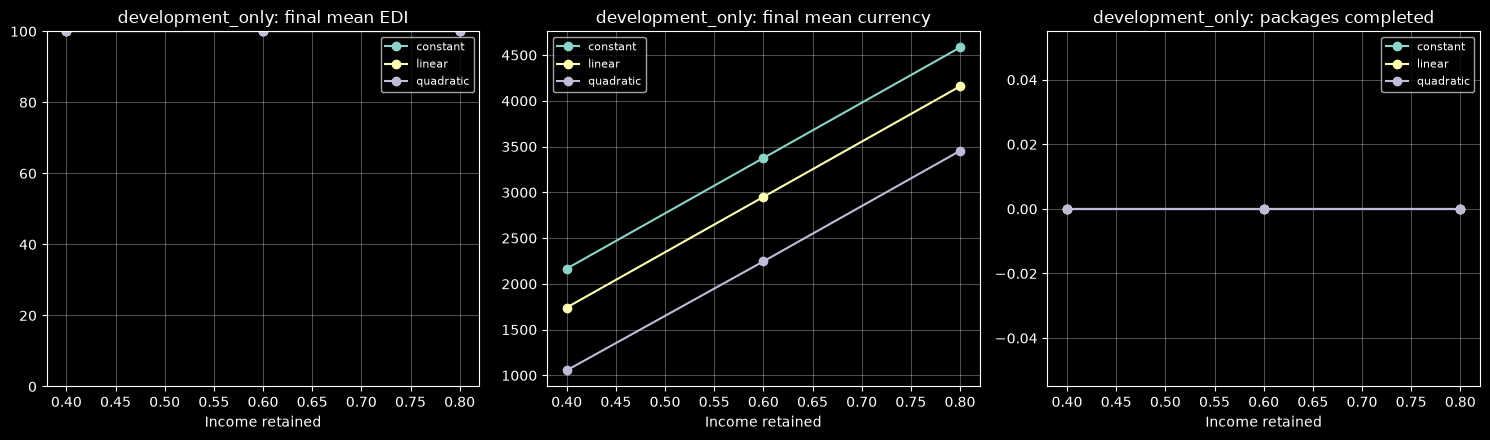

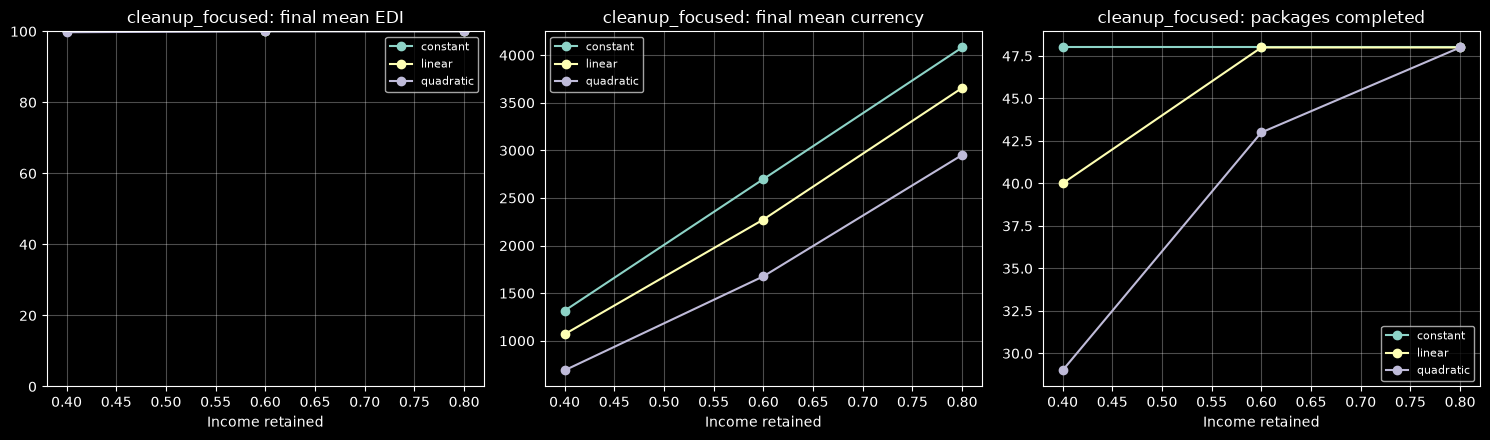

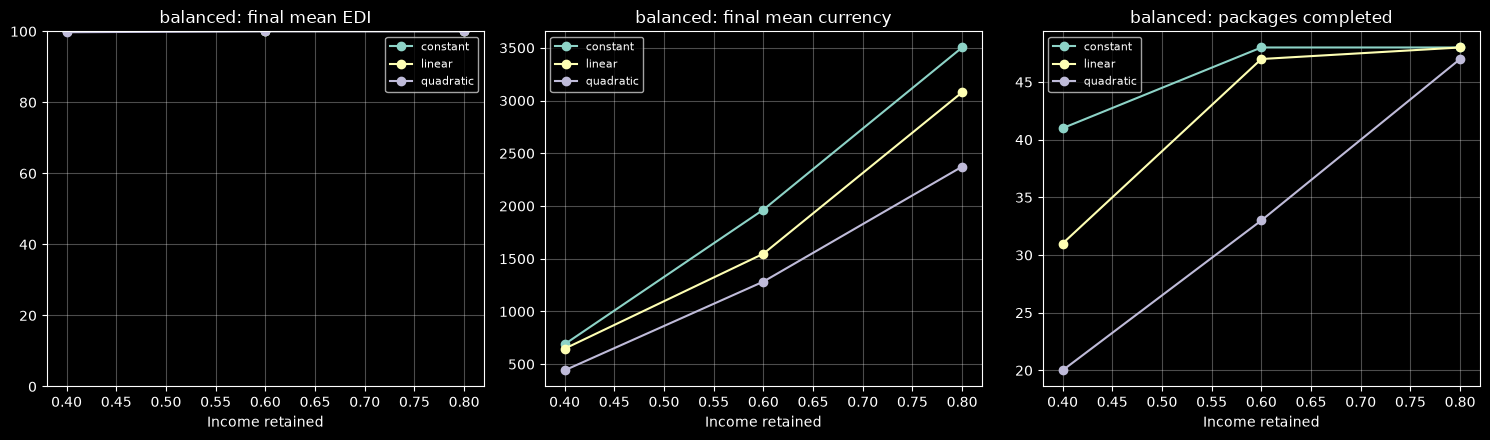

In [11]:
year_60_results = results[results["horizon_years"] == 60]

for policy_name in POLICIES:
    policy_rows = year_60_results[year_60_results["policy"] == policy_name]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    for cost_shape in DEVELOPMENT_COST_SHAPES:
        shape_rows = policy_rows[policy_rows["development_cost_shape"] == cost_shape]
        axes[0].plot(shape_rows["retention_fraction"], shape_rows["final_mean_EDI"], marker="o", label=cost_shape)
        axes[1].plot(shape_rows["retention_fraction"], shape_rows["final_mean_currency"], marker="o", label=cost_shape)
        axes[2].plot(shape_rows["retention_fraction"], shape_rows["investment_package_purchases"], marker="o", label=cost_shape)

    axes[0].set_title(policy_name + ": final mean EDI")
    axes[1].set_title(policy_name + ": final mean currency")
    axes[2].set_title(policy_name + ": packages completed")

    for axis in axes:
        axis.set_xlabel("Income retained")
        axis.grid(alpha=0.3)

    axes[0].set_ylim(0, 100)
    axes[0].legend(fontsize=8)
    axes[1].legend(fontsize=8)
    axes[2].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## Findings and limits

The cost curve has a clear but time-limited effect. At 20 years, linear costs produce the same mean EDI as constant costs in all nine policy-retention combinations. Quadratic costs lower mean EDI in two of nine combinations, by at most 1 point. At 40 years, quadratic costs lower mean EDI in five of nine combinations, by 1 to 4 points, and create more unaffordable development attempts. Linear costs change mean EDI in only one case, by 0.5 point. At 60 years, every policy reaches mean EDI 100 with constant and linear costs. Quadratic costs also reach 100 in seven of nine combinations; in the other two, mean EDI is 99.75 and the minimum regional EDI is 99.

At the 60% retention reference, all regions reach EDI 100 after 60 years under every policy and cost curve. Quadratic costs do change resource competition: balanced ends with 1,283 currency and 33 of 48 planned packages purchased, compared with 1,965 currency and 48 packages under constant costs. Cleanup-focused purchases 43 packages under quadratic costs versus 48 under constant costs. The Midwest and South are the first regions to miss development or investment attempts under the quadratic curve; the Northeast and West do not. That pattern is consistent with their lower starting currency and income, though all regions ultimately catch up in this deterministic 60-year scenario.

These results suggest quadratic costs add a temporary affordability constraint, especially around 40 years and for the Midwest and South. They do not create a lasting development ceiling in the reference case. Linear costs have little effect here, so constant costs remain the simplest baseline; quadratic costs are useful as a sensitivity case if the study needs to examine delayed development and stronger investment competition. The retention fractions and cost curves remain synthetic assumptions, not calibrated estimates.